# Build the preprocessing feature tables

Review the results from notebook 01 before extracting window and recording features.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.linalg import eigh
from scipy.signal import fftconvolve, periodogram, welch
from tqdm import tqdm

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
pd.set_option("display.max_colwidth", 100)

## Configure the extraction

Set the window quality rules and feature parameters.

In [2]:
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "capslpdb" / "recordings.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")
DATA_DIR = PROJECT_ROOT / "data" / "capslpdb"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "preprocessing"
REPORT_DIR = OUTPUT_DIR / "reports"
FIGURE_DIR = OUTPUT_DIR / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
RECORD_IDS = None
MAX_WINDOWS_PER_RECORDING = None
EPOCH_SECONDS = 30
EEG_BANDS = {"delta": (0.5, 4.0), "theta": (4.0, 8.0), "alpha": (8.0, 13.0), "beta": (13.0, 30.0)}
EEG_POWER = "relative"
WELCH_SECONDS = 4
CENTER_EMG = True
CLIPPING_REJECT_FRACTION = 0.01
FLAT_STEP_REJECT_FRACTION = 0.995
AMPLITUDE_FLAG_UV = {"eeg": 1000.0, "eog": 1500.0, "emg": 5000.0}
INCLUDE_FLAGGED_WINDOWS = True
RUN_SSA = False
SSA_LAG_SECONDS = 0.5
SSA_MIN_BAND_FRACTION = 0.6
CHANNEL_CANDIDATES = {
    "eeg": [("C4-A1",)],
    "eog": [("ROC-LOC",)],
    "emg": [("EMG1-EMG2",)],
}
FEATURE_COLUMNS = ["eeg_delta_power", "eeg_theta_power", "eeg_alpha_power", "eeg_beta_power", "eog_sd_uv", "emg_rms_uv"]
RECORDING_FEATURE_COLUMNS = [f"{feature}_{statistic}" for feature in FEATURE_COLUMNS for statistic in ("median", "p90")]
if any(low < 0 or high <= low for low, high in EEG_BANDS.values()):
    raise ValueError("EEG bands must have nonnegative, increasing bounds.")
if not 0 <= FLAT_STEP_REJECT_FRACTION <= 1 or any(value <= 0 for value in AMPLITUDE_FLAG_UV.values()):
    raise ValueError("Invalid flatness or amplitude thresholds.")
if EEG_POWER not in {"absolute", "relative"}:
    raise ValueError("EEG_POWER must be absolute or relative.")
if EPOCH_SECONDS <= 0 or WELCH_SECONDS > EPOCH_SECONDS:
    raise ValueError("Invalid window configuration.")
if not 0 <= CLIPPING_REJECT_FRACTION <= 1 or not 0 <= SSA_MIN_BAND_FRACTION <= 1:
    raise ValueError("Quality and SSA fractions must be between zero and one.")
if MAX_WINDOWS_PER_RECORDING is not None and MAX_WINDOWS_PER_RECORDING < 1:
    raise ValueError("MAX_WINDOWS_PER_RECORDING must be positive or None.")
if any(next_low != high for (_, high), (next_low, _) in zip(EEG_BANDS.values(), list(EEG_BANDS.values())[1:])):
    raise ValueError("The EEG bands must be contiguous.")
display(pd.DataFrame([
    {"Modality": "EEG", "Feature": name + " power", "Definition": f"{low:g}–{high:g} Hz; {EEG_POWER} power"}
    for name, (low, high) in EEG_BANDS.items()
] + [
    {"Modality": "EOG", "Feature": "Standard deviation", "Definition": "Population SD in µV"},
    {"Modality": "EMG", "Feature": "RMS", "Definition": "DC-centered RMS in µV" if CENTER_EMG else "Uncentered RMS in µV"},
]))

,Modality,Feature,Definition
0,EEG,delta power,0.5–4 Hz; relative power
1,EEG,theta power,4–8 Hz; relative power
2,EEG,alpha power,8–13 Hz; relative power
3,EEG,beta power,13–30 Hz; relative power
4,EOG,Standard deviation,Population SD in µV
5,EMG,RMS,DC-centered RMS in µV


## Read the channel selections

Use the files and channels saved by notebook 01.

In [3]:
mapping = pd.read_csv(DATA_DIR / "recordings.csv", dtype=str)
selection_path = REPORT_DIR / "channel_selections.csv"
if not selection_path.is_file():
    raise FileNotFoundError("Run notebook 01 to create reports/channel_selections.csv.")
channel_selections = pd.read_csv(selection_path, dtype=str).fillna("")
required = {"record_id", "class_name", "original_edf", "selected_edf", "status"}
required.update(f"{modality}_{field}" for modality in CHANNEL_CANDIDATES for field in ("indices", "channels", "units"))
if not required.issubset(channel_selections.columns) or channel_selections["record_id"].duplicated().any():
    raise ValueError("The channel selection CSV is incomplete or contains duplicate recordings. Run notebook 01 again.")
if set(mapping["record_id"]) != set(channel_selections["record_id"]):
    raise ValueError("The channel selection CSV does not match the recordings list. Run notebook 01 again.")
mapping = mapping.merge(channel_selections, on="record_id", validate="one_to_one", suffixes=("", "_selection"))
if not mapping["class_name"].eq(mapping["class_name_selection"]).all() or not mapping["edf_path"].eq(mapping["original_edf"]).all():
    raise ValueError("Recording metadata changed. Run notebook 01 again.")
unresolved = mapping.loc[~mapping["status"].isin(["selected", "excluded"]), "record_id"]
if not unresolved.empty:
    raise ValueError(f"Channel selections need review: {', '.join(unresolved)}")
display(mapping.loc[mapping["status"].eq("excluded"), ["record_id", "class_name", "issues"]])
mapping = mapping.loc[mapping["status"].eq("selected")].copy()
if RECORD_IDS is not None:
    missing_ids = set(RECORD_IDS) - set(mapping["record_id"])
    if missing_ids:
        raise ValueError(f"Unknown or excluded recording identifiers: {sorted(missing_ids)}")
    mapping = mapping[mapping["record_id"].isin(RECORD_IDS)].copy()
if mapping.empty:
    raise ValueError("No recordings were selected.")
mapping["edf_path"] = mapping["selected_edf"]
mapping = mapping.sort_values("record_id").reset_index(drop=True)
selections = mapping.set_index("record_id")

def recording_path(relative_path):
    path = (DATA_DIR / relative_path).resolve()
    if not path.is_relative_to(DATA_DIR.resolve()):
        raise ValueError("The recording path leaves the dataset directory.")
    return path

display(mapping.groupby("class_name").size().rename("recordings").to_frame())

,record_id,class_name,issues
0,brux1,other,Incomplete EDF data blocks and inconsistent recording length
17,n16,healthy,No EOG or EMG channels in the EDF header


,recordings
class_name,
healthy,15
other,69
rbd,22


## Read EDF signals at their native rates

Load the selected channels at their native sampling rates.

In [4]:
import sys
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from edf_quality import inspect_recordings, resolve_channel as _resolve_channel, read_montage, assess_window as _assess_window

def resolve_channel(edf, record_id, modality):
    row = selections.loc[record_id]
    indices = tuple(int(index) for index in row[f"{modality}_indices"].split(","))
    override = {record_id: {modality: indices}}
    selection = _resolve_channel(edf, record_id, modality, override, CHANNEL_CANDIDATES, EPOCH_SECONDS, EEG_BANDS)
    if selection is None:
        raise ValueError(f"The selected {modality.upper()} channel was not found.")
    actual = " minus ".join(f"{label} [index {index}]" for label, index in zip(selection["labels"], selection["indices"]))
    units = ", ".join(edf.units[index] for index in indices)
    if actual != row[f"{modality}_channels"] or units != row[f"{modality}_units"]:
        raise ValueError(f"The selected {modality.upper()} channel or unit changed. Run notebook 01 again.")
    return selection

def assess_window(values, clipped, modality):
    return _assess_window(values, clipped, modality, FLAT_STEP_REJECT_FRACTION, CLIPPING_REJECT_FRACTION, AMPLITUDE_FLAG_UV)

## Check the selected channels

Check the selected indices, labels and units against each EDF header.

In [5]:
headers, plans, inventory = inspect_recordings(mapping, recording_path, CHANNEL_CANDIDATES, resolve_channel)
display(pd.crosstab(inventory["class_name"], inventory["status"]))
display(inventory.loc[inventory["status"].ne("ready"), ["record_id", "class_name", "status", "reason"]])
if not plans:
    raise ValueError("No recordings have a complete valid channel mapping.")

Inspect EDF headers: 100%|██████████| 106/106 [00:00<00:00, 1449.09record/s]


status,ready
class_name,
healthy,15
other,69
rbd,22


,record_id,class_name,status,reason


## Define technical window quality checks

Reject non-finite, flat or substantially clipped windows while retaining high-amplitude warnings according to the configured policy. If digital limits do not match the samples, use 16-bit limits and flag the recording for calibration review.

## Define the optional EEG SSA comparison

Compare EEG features with an SSA reconstruction.

In [6]:
def ssa_eeg(values, sfreq):
    centered = np.asarray(values, dtype=float) - np.mean(values)
    lag = round(SSA_LAG_SECONDS * sfreq)
    if not 2 <= lag <= len(centered) // 2:
        raise ValueError("SSA lag must be between two samples and half the epoch length.")
    trajectory = np.ascontiguousarray(sliding_window_view(centered, lag).T)
    columns = trajectory.shape[1]
    eigenvalues, vectors = eigh(trajectory @ trajectory.T / columns, check_finite=False)
    eigenvalues, vectors = np.maximum(eigenvalues[::-1], 0), vectors[:, ::-1]
    frequencies, power = periodogram(vectors, fs=sfreq, window="boxcar", detrend=False, axis=0)
    ranges = [(0.0, next(iter(EEG_BANDS.values()))[0]), *EEG_BANDS.values(), (max(high for low, high in EEG_BANDS.values()), np.inf)]
    contributions = np.array([power[(frequencies >= low) & (frequencies < high)].sum(axis=0) for low, high in ranges])
    contributions /= np.maximum(power.sum(axis=0), np.finfo(float).tiny)
    assignment = np.argmax(contributions, axis=0)
    counts = np.convolve(np.ones(lag), np.ones(columns))
    groups = {}
    selected_counts = {}
    for group_number, band in enumerate(EEG_BANDS, start=1):
        selected = np.flatnonzero((assignment == group_number) & (contributions[group_number] >= SSA_MIN_BAND_FRACTION) & (eigenvalues > eigenvalues.max() * 1e-12))
        selected_counts[band] = int(len(selected))
        reconstructed = np.zeros(len(centered))
        if len(selected):
            scores = vectors[:, selected].T @ trajectory
            for row, index in enumerate(selected):
                reconstructed += fftconvolve(vectors[:, index], scores[row], mode="full") / counts
        groups[band] = reconstructed
    if not any(selected_counts.values()):
        raise ValueError("SSA retained no components under the configured frequency rule.")
    return np.sum(list(groups.values()), axis=0), groups, selected_counts

## Define the six numerical features

Integrate Welch power over fixed EEG bands and compute EOG SD and EMG RMS from their native samples.

In [7]:
def band_integral(frequencies, power, low, high):
    inside = (frequencies > low) & (frequencies < high)
    grid = np.r_[low, frequencies[inside], high]
    selected_power = np.r_[np.interp(low, frequencies, power), power[inside], np.interp(high, frequencies, power)]
    return float(np.trapezoid(selected_power, grid))

def eeg_features(values, sfreq):
    segment = min(len(values), round(WELCH_SECONDS * sfreq))
    frequencies, power = welch(values, fs=sfreq, window="hann", nperseg=segment, noverlap=segment // 2, detrend="constant", scaling="density")
    band_power = {f"eeg_{name}_power": band_integral(frequencies, power, low, high) for name, (low, high) in EEG_BANDS.items()}
    total = sum(band_power.values())
    if total <= 0 or not np.isfinite(total):
        raise ValueError("EEG band power is not positive and finite.")
    if EEG_POWER == "relative":
        band_power = {name: value / total for name, value in band_power.items()}
    return band_power

def extract_features(signals, rates, eeg_override=None):
    eeg = signals["eeg"] if eeg_override is None else eeg_override
    emg = signals["emg"] - np.mean(signals["emg"]) if CENTER_EMG else signals["emg"]
    features = {**eeg_features(eeg, rates["eeg"]), "eog_sd_uv": float(np.std(signals["eog"], ddof=0)), "emg_rms_uv": float(np.sqrt(np.mean(emg ** 2)))}
    if not np.isfinite(list(features.values())).all():
        raise ValueError("Feature extraction produced non-finite values.")
    return features

## Load one complete recording and process its windows

Process the 30-second windows of one recording.

In [8]:
def process_record(record, max_windows=None, use_ssa=None):
    record_id = record["record_id"]
    edf = headers[record_id]
    plan = plans[record_id]
    use_ssa = RUN_SSA if use_ssa is None else use_ssa
    full_windows = int(np.floor(edf.duration / EPOCH_SECONDS))
    count = min(full_windows, max_windows) if max_windows is not None else full_windows
    if count == 0:
        raise ValueError("Recording contains no complete epoch.")
    variants = {"baseline": []}
    if use_ssa:
        variants["ssa"] = []
    rates = {modality: selection["sfreq"] for modality, selection in plan.items()}
    with edf:
        loaded = {modality: read_montage(edf, selection) for modality, selection in plan.items()}
        range_issues = [f"{modality.upper()}: {edf.labels[index]}" for modality, selection in plan.items()
                        for index in selection["indices"] if not edf.digital_limits(index)[2]]
    range_issues = ", ".join(range_issues)
    loaded_megabytes = sum(values.nbytes + clipped.nbytes for values, clipped in loaded.values()) / 1024 ** 2
    samples_per_epoch = {modality: round(EPOCH_SECONDS * rates[modality]) for modality in plan}
    for index in range(count):
        signals = {modality: loaded[modality][0][index * samples:(index + 1) * samples] for modality, samples in samples_per_epoch.items()}
        clipping = {modality: loaded[modality][1][index * samples:(index + 1) * samples] for modality, samples in samples_per_epoch.items()}
        quality = {modality: assess_window(signals[modality], clipping[modality], modality) for modality in plan}
        rejections = [reason for item in quality.values() for reason in item["reject"]]
        flags = [reason for item in quality.values() for reason in item["flags"]]
        accepted = not rejections and (INCLUDE_FLAGGED_WINDOWS or not flags)
        base = {
            "record_id": record_id, "class_name": record["class_name"], "original_group": record["original_group"],
            "window_index": index, "start_seconds": index * EPOCH_SECONDS, "duration_seconds": EPOCH_SECONDS,
            "accepted": accepted, "quality_status": "exclude" if not accepted else ("flag" if flags else "keep"),
            "quality_reasons": ";".join(rejections + flags),
            "alternate_montage": any(selection["alternate"] for selection in plan.values()),
            "edf_path": record["edf_path"], "selection_issues": record["issues"], "digital_range_issues": range_issues,
        }
        for modality in plan:
            base[f"{modality}_sfreq_hz"] = rates[modality]
            base[f"{modality}_channels"] = " minus ".join(plan[modality]["labels"])
            base[f"{modality}_ptp_uv"] = quality[modality]["ptp_uv"]
            base[f"{modality}_clipping_fraction"] = quality[modality]["clip_fraction"]
        for variant in variants:
            result = {**base, **dict.fromkeys(FEATURE_COLUMNS, np.nan)}
            if accepted:
                try:
                    if variant == "ssa":
                        reconstructed, _, component_counts = ssa_eeg(signals["eeg"], rates["eeg"])
                        result.update(extract_features(signals, rates, eeg_override=reconstructed))
                        result.update({f"ssa_{band}_components": n for band, n in component_counts.items()})
                    else:
                        result.update(extract_features(signals, rates))
                except (ValueError, np.linalg.LinAlgError, FloatingPointError) as exc:
                    result.update({"accepted": False, "quality_status": "exclude", "quality_reasons": ";".join(filter(None, [base["quality_reasons"], f"{variant}_feature_error: {exc}"]))})
            variants[variant].append(result)
    info = {"record_id": record_id, "duration_seconds": edf.duration, "loaded_megabytes": loaded_megabytes, "complete_windows": full_windows, "processed_windows": count, "trailing_seconds": edf.duration - full_windows * EPOCH_SECONDS, "limited_run": count < full_windows, "digital_range_issues": range_issues}
    return {name: pd.DataFrame(rows) for name, rows in variants.items()}, info

## Preview a window

Inspect the selected EEG, EOG and EMG signals and the EEG spectrum.

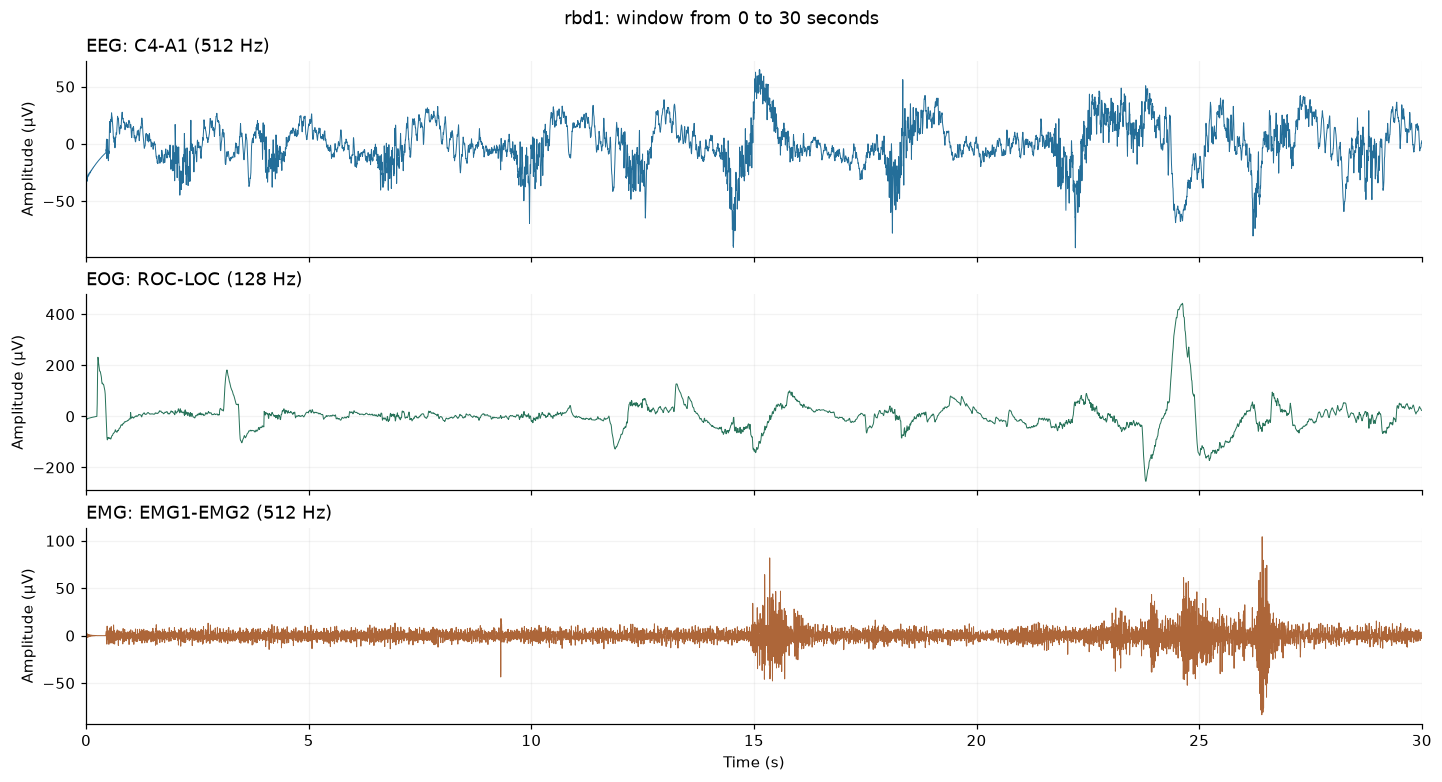

,reject,flags,ptp_uv,clip_fraction
eeg,[],[],155.433455,0.0
eog,[],[],696.69083,0.0
emg,[],[],187.637275,0.0


,eeg_delta_power,eeg_theta_power,eeg_alpha_power,eeg_beta_power,eog_sd_uv,emg_rms_uv
0,0.769825,0.113538,0.037531,0.079107,63.006713,7.535837


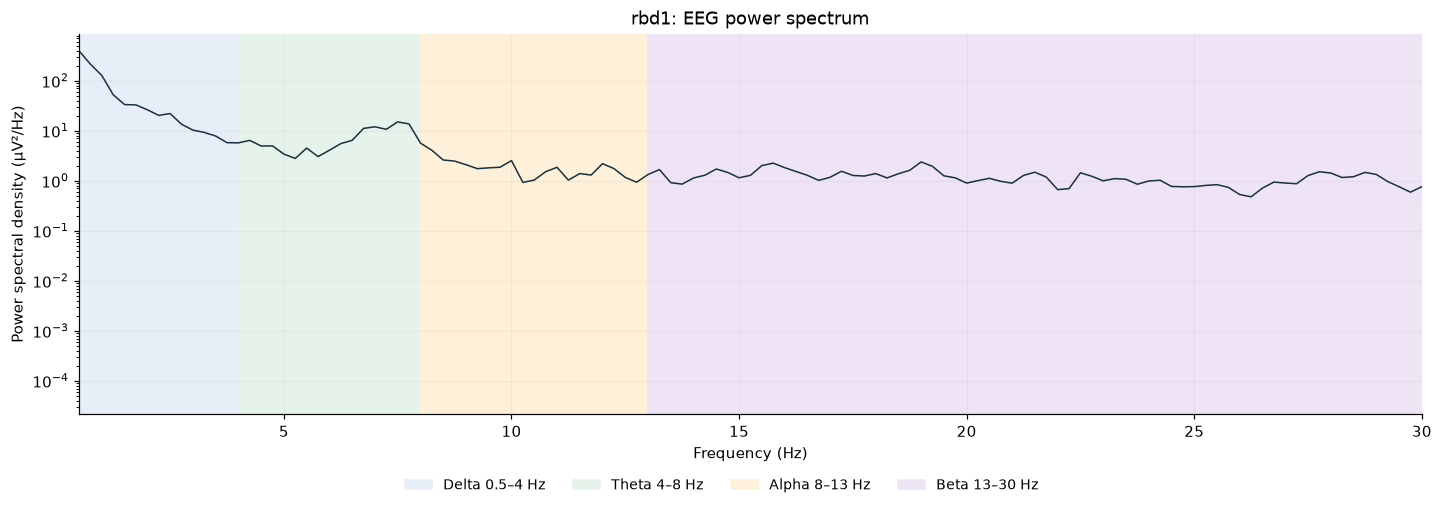

In [9]:
preview_id = "rbd1" if "rbd1" in plans else next(iter(plans))
preview_edf = headers[preview_id]
preview_plan = plans[preview_id]
preview_rates = {modality: selection["sfreq"] for modality, selection in preview_plan.items()}
preview_signals = None
with preview_edf:
    for preview_index in range(min(10, int(preview_edf.duration // EPOCH_SECONDS))):
        preview_blocks = {modality: read_montage(preview_edf, selection, preview_index * round(EPOCH_SECONDS * selection["sfreq"]), (preview_index + 1) * round(EPOCH_SECONDS * selection["sfreq"])) for modality, selection in preview_plan.items()}
        preview_signals = {modality: block[0] for modality, block in preview_blocks.items()}
        preview_qc = {modality: assess_window(preview_signals[modality], preview_blocks[modality][1], modality) for modality in preview_plan}
        if not any(item["reject"] for item in preview_qc.values()):
            break
if preview_signals is None:
    raise ValueError("No complete preview window exists.")
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True, layout="constrained")
for ax, (modality, values), color in zip(axes, preview_signals.items(), ["#246e99", "#28735a", "#ad6639"]):
    time = np.arange(len(values)) / preview_rates[modality]
    ax.plot(time, values, color=color, linewidth=0.65)
    ax.set_title(f"{modality.upper()}: {' minus '.join(preview_plan[modality]['labels'])} ({preview_rates[modality]:g} Hz)", loc="left")
    ax.set_ylabel("Amplitude (µV)")
    ax.grid(alpha=0.15)
axes[-1].set(xlabel="Time (s)", xlim=(0, EPOCH_SECONDS))
fig.suptitle(f"{preview_id}: window from {preview_index * EPOCH_SECONDS:g} to {(preview_index + 1) * EPOCH_SECONDS:g} seconds")
fig.savefig(FIGURE_DIR / "preprocessing_signal_preview.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
preview_valid = not any(item["reject"] for item in preview_qc.values())
display(pd.DataFrame(preview_qc).T)
if preview_valid:
    display(pd.DataFrame([extract_features(preview_signals, preview_rates)]))
frequencies, power = welch(preview_signals["eeg"], fs=preview_rates["eeg"], window="hann", nperseg=round(WELCH_SECONDS * preview_rates["eeg"]), noverlap=round(WELCH_SECONDS * preview_rates["eeg"]) // 2, scaling="density")
fig, ax = plt.subplots(figsize=(13, 4.5), layout="constrained")
for (name, (low, high)), color in zip(EEG_BANDS.items(), ["#e7eef8", "#e6f3eb", "#fff0d9", "#eee4f6"]):
    ax.axvspan(low, high, color=color, label=f"{name.title()} {low:g}–{high:g} Hz")
ax.semilogy(frequencies, np.maximum(power, np.finfo(float).tiny), color="#19323f", linewidth=1)
ax.set(xlim=(0.5, 30), xlabel="Frequency (Hz)", ylabel="Power spectral density (µV²/Hz)", title=f"{preview_id}: EEG power spectrum")
ax.grid(alpha=0.15)
handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside lower center", ncols=4, fontsize=9)
fig.savefig(FIGURE_DIR / "preprocessing_eeg_spectrum.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
if RUN_SSA and preview_valid:
    preview_ssa, _, preview_counts = ssa_eeg(preview_signals["eeg"], preview_rates["eeg"])
    display(pd.DataFrame([preview_counts], index=["retained components"]))
    display(pd.DataFrame([extract_features(preview_signals, preview_rates, preview_ssa)], index=["SSA comparison"]))

## Extract all configured recordings

Extract features for each recording.

In [10]:
frames = {name: [] for name in (["baseline", "ssa"] if RUN_SSA else ["baseline"])}
run_rows = []
progress = tqdm(mapping.to_dict("records"), desc="Extract recordings", unit="record")
for record in progress:
    record_id = record["record_id"]
    inventory_row = inventory.loc[inventory["record_id"].eq(record_id)].iloc[0]
    if record_id not in plans:
        run_rows.append({**record, "status": inventory_row["status"], "reason": inventory_row["reason"]})
        continue
    try:
        current, info = process_record(record, max_windows=MAX_WINDOWS_PER_RECORDING)
        for variant, table in current.items():
            frames[variant].append(table)
        run_rows.append({**record, **info, "status": "processed", "reason": ""})
        progress.set_postfix(record=record_id, windows=info["processed_windows"])
    except (OSError, ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
        run_rows.append({**record, "status": "processing_failed", "reason": f"{type(exc).__name__}: {exc}"})
run_report = pd.DataFrame(run_rows)
display(run_report.groupby(["class_name", "status"]).size().rename("recordings").to_frame())
failed = run_report.loc[run_report["status"].ne("processed"), ["record_id", "class_name", "status", "reason"]]
if not failed.empty:
    display(failed.reset_index(drop=True))
if not frames["baseline"]:
    raise RuntimeError("No recording was processed. Review the errors above.")
window_tables = {variant: pd.concat(tables, ignore_index=True) for variant, tables in frames.items()}

Extract recordings: 100%|██████████| 106/106 [01:59<00:00,  1.13s/record, record=sdb4, windows=1303] 


,,recordings
class_name,status,
healthy,processed,15
other,processed,69
rbd,processed,22


## Aggregate windows and export CSV files

Calculate the median and P90 of each feature across accepted windows.

In [11]:
def summarize_recordings(windows):
    rows = []
    for record_id, all_windows in windows.groupby("record_id", sort=True):
        retained = all_windows.loc[all_windows["accepted"].eq(True)]
        if retained.empty:
            continue
        first = all_windows.iloc[0]
        row = {"record_id": record_id, "class_name": first["class_name"], "original_group": first["original_group"], "total_windows": len(all_windows), "retained_windows": len(retained), "rejected_windows": len(all_windows) - len(retained), "flagged_windows": int(all_windows["quality_status"].eq("flag").sum()), "retention_fraction": len(retained) / len(all_windows), "alternate_montage": bool(first["alternate_montage"]), "edf_path": first["edf_path"], "selection_issues": first["selection_issues"], "digital_range_issues": first["digital_range_issues"]}
        for modality in CHANNEL_CANDIDATES:
            row[f"{modality}_channels"] = first[f"{modality}_channels"]
        for feature in FEATURE_COLUMNS:
            values = retained[feature].to_numpy(dtype=float)
            row[f"{feature}_median"] = float(np.median(values))
            row[f"{feature}_p90"] = float(np.quantile(values, 0.90, method="linear"))
        rows.append(row)
    columns = ["record_id", "class_name", "original_group", "total_windows", "retained_windows", "rejected_windows", "flagged_windows", "retention_fraction", "alternate_montage", "edf_path", "selection_issues", "digital_range_issues", "eeg_channels", "eog_channels", "emg_channels", *RECORDING_FEATURE_COLUMNS]
    return pd.DataFrame(rows, columns=columns)

exports = []
recording_tables = {}
for variant, windows in window_tables.items():
    if windows.duplicated(["record_id", "window_index"]).any():
        raise ValueError(f"Duplicate windows in {variant}.")
    valid = windows.loc[windows["accepted"].eq(True), FEATURE_COLUMNS]
    if not np.isfinite(valid.to_numpy(dtype=float)).all():
        raise ValueError(f"Accepted windows contain invalid features in {variant}.")
    if EEG_POWER == "relative" and len(valid):
        if not np.allclose(valid[FEATURE_COLUMNS[:4]].sum(axis=1), 1, atol=1e-8):
            raise ValueError("Relative EEG band powers do not sum to one.")
    recordings = summarize_recordings(windows)
    if recordings["record_id"].duplicated().any() or not np.isfinite(recordings[RECORDING_FEATURE_COLUMNS].to_numpy(dtype=float)).all():
        raise ValueError("Invalid recording feature table.")
    recording_tables[variant] = recordings
    if variant == "baseline":
        for name, table in [("features_windows.csv", windows), ("features_recordings.csv", recordings)]:
            destination = OUTPUT_DIR / name
            temporary = destination.with_suffix(".tmp")
            table.to_csv(temporary, index=False, encoding="utf-8")
            temporary.replace(destination)
            exports.append({"file": name, "rows": len(table)})
display(pd.DataFrame(exports))
display(recording_tables["baseline"].head())

,file,rows
0,features_windows.csv,118966
1,features_recordings.csv,106


,record_id,class_name,original_group,total_windows,retained_windows,rejected_windows,flagged_windows,retention_fraction,alternate_montage,edf_path,...,eeg_theta_power_median,eeg_theta_power_p90,eeg_alpha_power_median,eeg_alpha_power_p90,eeg_beta_power_median,eeg_beta_power_p90,eog_sd_uv_median,eog_sd_uv_p90,emg_rms_uv_median,emg_rms_uv_p90
0,brux2,other,brux,1044,1044,0,3,1.000000,False,other/brux2/brux2.edf,...,0.128300,0.187566,0.086887,0.379716,0.114536,0.178522,9.879764,27.304918,2.134399,5.334040
1,ins1,other,ins,1600,1600,0,16,1.000000,False,other/ins1/ins1.edf,...,0.099431,0.148873,0.128485,0.248054,0.127345,0.271921,21.509330,113.424978,3.811827,11.335992
2,ins2,other,ins,1675,1675,0,0,1.000000,False,other/ins2/ins2.edf,...,0.105077,0.220313,0.105830,0.198434,0.246028,0.511901,17.335047,64.434337,3.226831,23.195315
3,ins3,other,ins,1030,1030,0,1,1.000000,False,other/ins3/ins3.edf,...,0.153532,0.232866,0.133147,0.236402,0.133384,0.295384,11.355293,31.221259,6.667305,24.390826
4,ins4,other,ins,1273,1271,2,38,0.998429,False,other/ins4/ins4.edf,...,0.116257,0.200088,0.113466,0.184243,0.120694,0.322808,29.591623,122.366586,6.156771,33.677407


## Inspect quality retention and cohort coverage

Compare retained windows and exported recordings by class before using the CSV tables for classification.

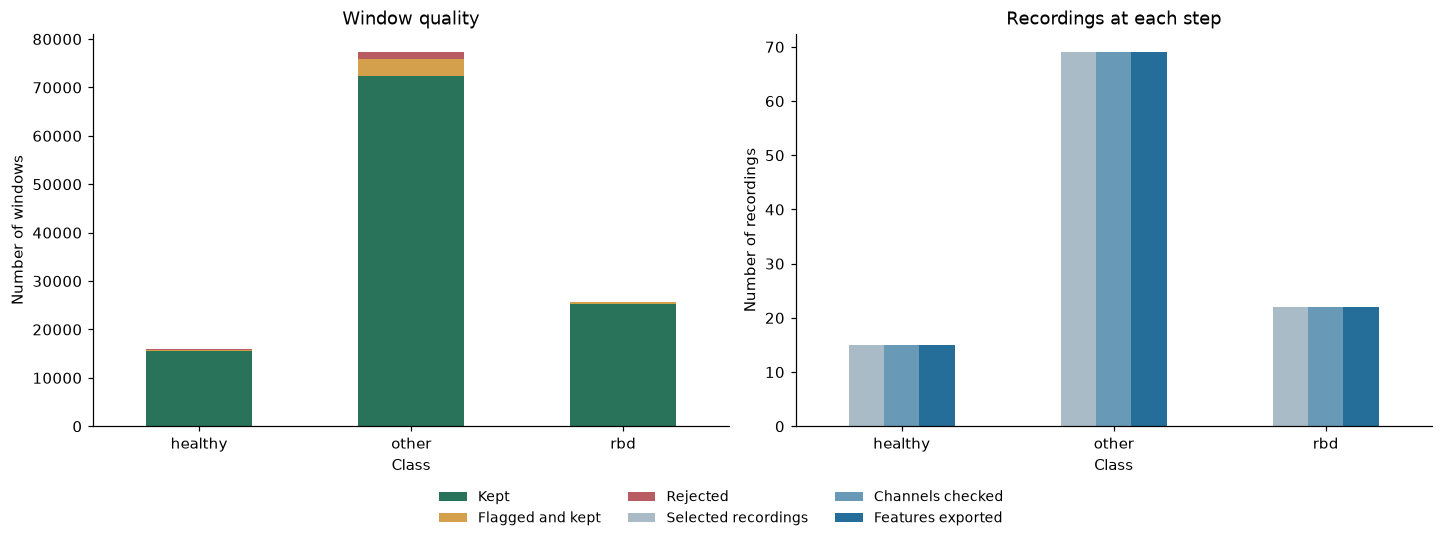

,Selected recordings,Channels checked,Features exported
class_name,,,
healthy,15,15,15
other,69,69,69
rbd,22,22,22


quality_status,keep,flag,exclude
class_name,,,
healthy,15503,342,200
other,72450,3531,1279
rbd,25317,333,11


In [12]:
baseline_windows = window_tables["baseline"]
quality_counts = pd.crosstab(baseline_windows["class_name"], baseline_windows["quality_status"]).reindex(columns=["keep", "flag", "exclude"], fill_value=0)
coverage = pd.DataFrame({
    "Selected recordings": mapping.groupby("class_name").size(),
    "Channels checked": inventory[inventory["status"].eq("ready")].groupby("class_name").size(),
    "Features exported": recording_tables["baseline"].groupby("class_name").size(),
}).fillna(0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
quality_counts.plot.bar(stacked=True, ax=axes[0], color=["#28735a", "#d5a04b", "#b85c62"], legend=False, rot=0)
coverage.plot.bar(ax=axes[1], color=["#a9bbc6", "#689ab7", "#246e99"], legend=False, rot=0)
axes[0].set(title="Window quality", xlabel="Class", ylabel="Number of windows")
axes[1].set(title="Recordings at each step", xlabel="Class", ylabel="Number of recordings")
handles_left, labels_left = axes[0].get_legend_handles_labels()
handles_right, labels_right = axes[1].get_legend_handles_labels()
quality_labels = {"keep": "Kept", "flag": "Flagged and kept", "exclude": "Rejected"}
fig.legend(handles_left + handles_right, [quality_labels[label] for label in labels_left] + labels_right, loc="outside lower center", ncols=3, fontsize=9)
fig.savefig(FIGURE_DIR / "preprocessing_quality_summary.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
display(coverage)
display(quality_counts)
missing_exports = mapping.loc[~mapping["record_id"].isin(recording_tables["baseline"]["record_id"]), ["record_id", "class_name"]]
if not missing_exports.empty:
    display(missing_exports)